# Customer Churn Prediction

## 1. Project Overview

Customer churn refers to a situation where customers stop using a company's products or services. Predicting customer churn helps businesses identify customers who are likely to leave and take steps to improve customer retention.

In this project, we will analyze customer data and build machine learning models to predict whether a customer is likely to churn.

## 2. Project Objectives

- Understand and explore the customer dataset.
- Identify patterns and factors associated with customer churn.
- Perform data cleaning and preprocessing.
- Train and compare different machine learning classification models.
- Evaluate model performance using appropriate metrics.
- Derive business insights from the analysis.

## 3. Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

## 4. Machine Learning Approach

This is a **supervised machine learning classification problem** because the dataset contains a target column, `Churn`, that indicates whether a customer has left the service.

In [13]:
import sys
print(sys.executable)

c:\Users\krish\AppData\Local\Programs\Python\Python313\python.exe


In [14]:
import pandas as pd
print(pd.__version__)

3.0.6


In [15]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [16]:
df.shape

(7043, 21)

## 5. Dataset Exploration

In this section, we will explore the dataset's dimensions, column names, data types, and missing values to understand the data before preprocessing.

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [18]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## 6. Initial Dataset Observations

- The dataset contains 7,043 customer records and 21 columns.
- The target variable is `Churn`.
- The dataset contains numerical features such as `tenure`, `MonthlyCharges`, and `SeniorCitizen`.
- It also contains categorical features such as `Contract`, `InternetService`, and `PaymentMethod`.
- The initial missing-value check reports no null values.
- The `TotalCharges` column is stored as a string, so we need to investigate whether it contains blank or invalid values before modeling.

In [19]:
print(df["TotalCharges"].dtype)
blank_charges = df["TotalCharges"].str.strip().eq("").sum()
print("Blank Total_Charges Value:",blank_charges)

str
Blank Total_Charges Value: 11


In [20]:
df["Churn"].value_counts(normalize=True)*100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

### Churn Distribution Analysis

The dataset contains approximately 73.46% customers who stayed and 26.54% customers who churned.

This indicates that customer churn is a significant business concern. Since the two classes are not equally represented, model evaluation should include metrics such as precision, recall, and F1-score in addition to accuracy.

In [21]:
df[df["TotalCharges"].str.strip()== ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [22]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(),errors="coerce")
df["TotalCharges"].isnull().sum()

np.int64(11)

In [23]:
df["TotalCharges"].dtype

dtype('float64')

## 7. Exploratory Data Analysis (EDA)

### 7.1 Customer Tenure and Churn

In this analysis, we will compare customer tenure across churn groups to investigate whether customers who have stayed for shorter periods are more likely to churn.

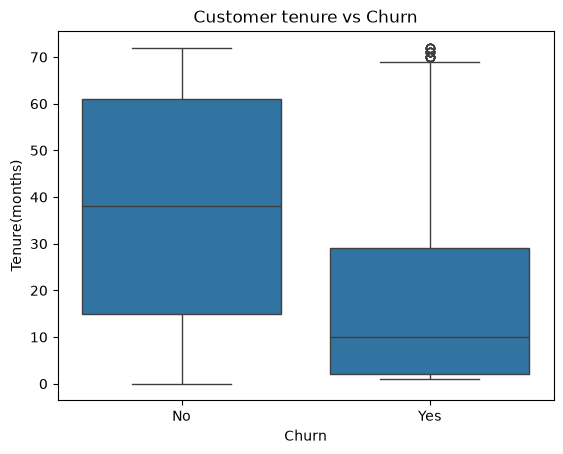

In [26]:
import matplotlib.pyplot as plt 
import seaborn as sns
sns.boxplot(data=df,x="Churn",y="tenure")
plt.title("Customer tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure(months)")
plt.show()

**Observation:** Customers who churned generally had lower tenure than customers who stayed. This suggests that newer customers may be at a higher risk of churn. Further analysis is needed to investigate other factors associated with churn.

In [27]:
churn_by_contract = pd.crosstab(df["Contract"],df["Churn"],normalize="index")*100
churn_by_contract

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


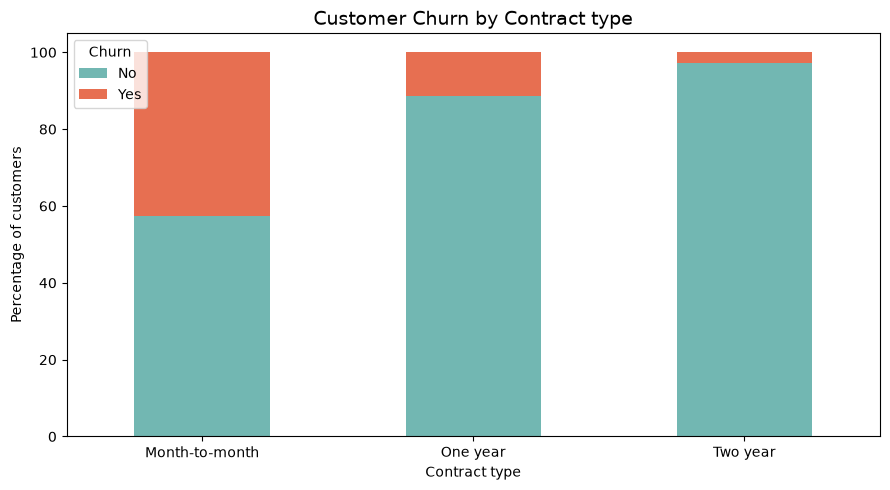

In [31]:
churn_by_contract.plot(kind='bar',stacked=True,figsize=(9,5),color = ("#72B7B2", "#E76F51"))
plt.title("Customer Churn by Contract type",fontsize=14)
plt.xlabel("Contract type")
plt.ylabel("Percentage of customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()


**Observation:** Customers with month-to-month contracts have the highest churn rate (42.71%), followed by customers with one-year contracts (11.27%). Customers with two-year contracts have the lowest churn rate (2.83%).

**Business Insight:** The company should investigate why month-to-month customers leave more frequently and consider testing retention strategies, such as improved customer support or suitable long-term contract offers.

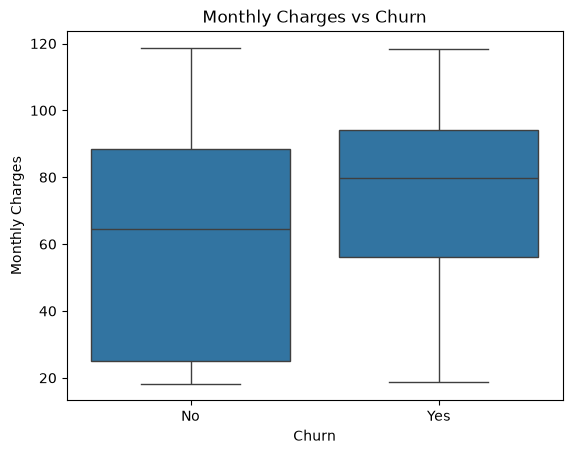

In [32]:
sns.boxplot(data=df,x="Churn",y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

**Observation:** Customers who churned had a higher median monthly charge (approximately 80) than customers who stayed (approximately 65). The monthly charges of customers who stayed also showed a wider spread within the middle 50% of the data.

**Business Insight:** Higher monthly charges may be associated with customer churn. The company could investigate whether pricing or perceived value for money influences customers' decisions to leave.

In [33]:
churn_by_payment = pd.crosstab(df["PaymentMethod"],df["Churn"],normalize="index")*100
churn_by_payment

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


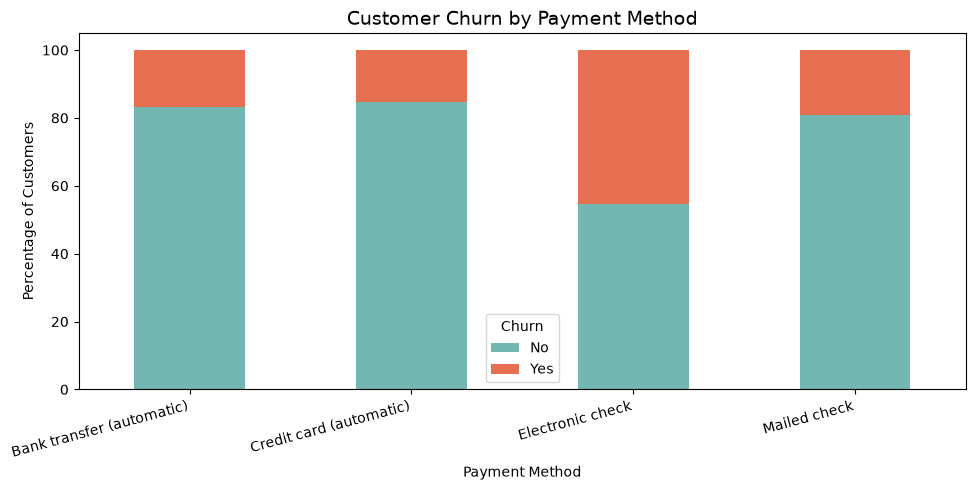

In [36]:
churn_by_payment.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=("#72B7B2", "#E76F51")
)

plt.title("Customer Churn by Payment Method", fontsize=14)
plt.xlabel("Payment Method")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=15, ha="right")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

**Observation:** Customers using electronic checks have the highest churn rate (45.29%), followed by mailed checks (19.11%), bank transfers (16.71%), and credit cards (15.24%).

**Business Insight:** The company should investigate why electronic check users leave more frequently and evaluate whether payment experience, convenience, or other customer characteristics are associated with their higher churn rate.

In [37]:
churn_by_internet = pd.crosstab(df["InternetService"],df["Churn"],normalize="index")*100
churn_by_internet

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


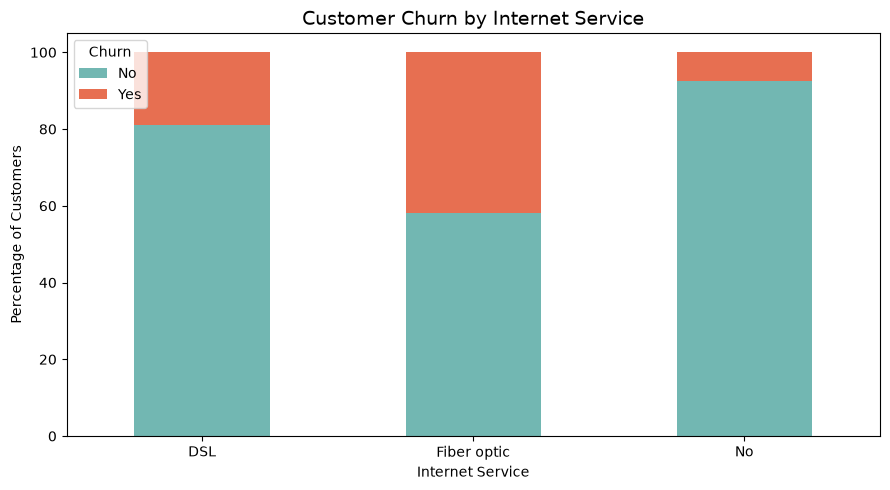

In [38]:
churn_by_internet.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=("#72B7B2", "#E76F51")
)

plt.title("Customer Churn by Internet Service", fontsize=14)
plt.xlabel("Internet Service")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()


**Observation:** Customers using Fiber optic internet service have the highest churn rate (41.89%), followed by DSL users (18.96%). Customers without internet service have the lowest churn rate (7.40%).

**Business Insight:** The company should investigate why Fiber optic customers leave more frequently. Possible areas to explore include service quality, pricing, and customer satisfaction before deciding on retention strategies.

In [40]:
churn_by_support = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

churn_by_support

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


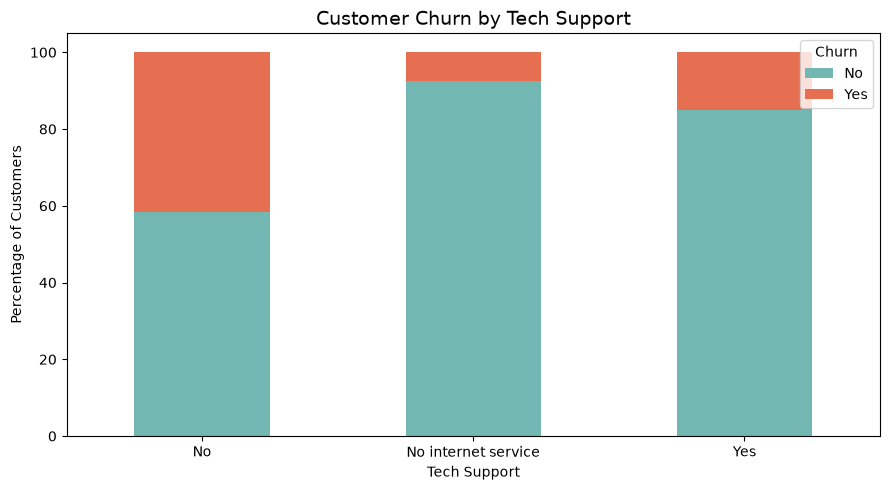

In [41]:
churn_by_support.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=("#72B7B2", "#E76F51")
)

plt.title("Customer Churn by Tech Support", fontsize=14)
plt.xlabel("Tech Support")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

**Observation:** Customers without technical support have the highest churn rate (41.64%). Customers with technical support have a lower churn rate (15.17%), while customers with no internet service have the lowest churn rate (7.40%).

**Business Insight:** The company could investigate whether better access to technical support helps improve customer retention. It should also explore why customers without technical support leave more frequently.

In [42]:
churn_by_security = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

churn_by_security

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


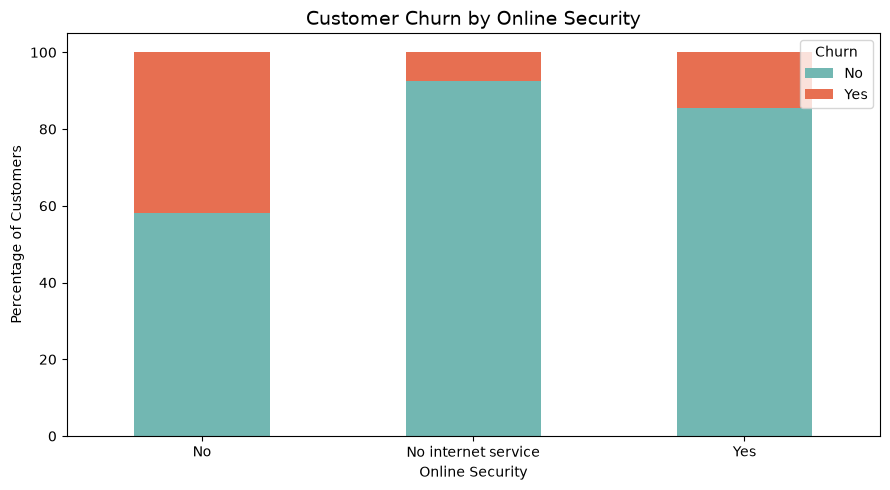

In [43]:
churn_by_security.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=("#72B7B2", "#E76F51")
)

plt.title("Customer Churn by Online Security", fontsize=14)
plt.xlabel("Online Security")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

**Observation:** Customers without online security have the highest churn rate (41.77%). Customers with online security have a lower churn rate (14.61%), while customers with no internet service have the lowest churn rate (7.40%).

**Business Insight:** The company could investigate whether online security services improve customer satisfaction and retention. It should explore why customers without online security leave more frequently before deciding on suitable retention strategies.

In [44]:
churn_by_billing = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
) * 100

churn_by_billing

Churn,No,Yes
PaperlessBilling,,
No,83.669916,16.330084
Yes,66.434908,33.565092


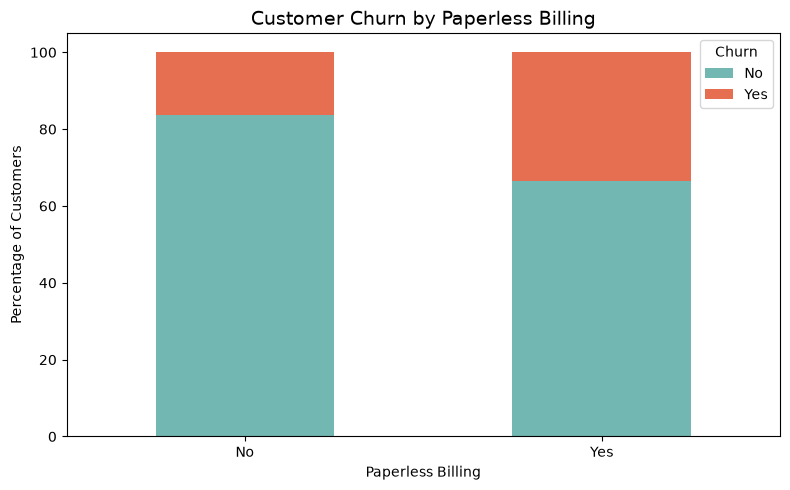

In [45]:
churn_by_billing.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=("#72B7B2", "#E76F51")
)

plt.title("Customer Churn by Paperless Billing", fontsize=14)
plt.xlabel("Paperless Billing")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

**Observation:** Customers who use paperless billing have a higher churn rate (33.57%) than customers who do not use paperless billing (16.33%).

**Business Insight:** The company could investigate whether paperless billing is associated with other factors that influence churn, such as payment methods, contract types, or customer preferences. It should avoid assuming that paperless billing itself causes customers to leave.

In [46]:
churn_by_senior = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

churn_by_senior

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


In [ ]:
churn_by_senior.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=("#72B7B2", "#E76F51")
)

plt.title("Customer Churn by Senior Citizen status", fontsize=14)
plt.xlabel("Senior Citizen(0=No, 1 = Yes)")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()